# Gym Churn: Customer Clustering

This notebook groups Model Fitness customers into clusters based on their characteristics, using hierarchical clustering to estimate the number of groups and K-means to assign customers to them. Each cluster is then profiled and compared by churn rate to identify which customer groups are most likely to leave and which are most loyal.

In [1]:
# Libraries for data handling, clustering and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)  # show all columns in outputs

## 1. Data Preparation for Clustering

In [2]:
# Load the cleaned dataset prepared in notebook 01
gym_data = pd.read_csv('../data/gym_churn_clean.csv')
gym_data.head()

,gender,near_location,partner,promo_friends,phone,contract_period,group_visits,age,avg_additional_charges_total,month_to_end_contract,lifetime,avg_class_frequency_total,avg_class_frequency_current_month,churn
0,1,1,1,1,0,6,1,29,14.227470,5,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1,3,1.113884,1.120078,0


In [3]:
# Set the churn column aside: clusters are built only from customer characteristics
# One feature from each highly correlated pair is dropped, as in notebook 02
X = gym_data.drop(
    columns=['churn', 'month_to_end_contract', 'avg_class_frequency_total'])

print(X.shape)

(4000, 11)


In [4]:
# Standardize features so that all of them contribute equally to the distances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Observations
- The churn column is set aside, so clusters are based only on customer characteristics; churn is used later to compare the clusters.
- As in the modeling notebook, `month_to_end_contract` and `avg_class_frequency_total` are excluded, since they almost duplicate other features and would be counted twice in the distance calculations.
- All features are standardized so that each contributes equally to the distances between customers. The scaler is fitted on the full dataset, since clustering does not involve a validation set.

## 2. Number of Clusters (Dendrogram)

In [5]:
# Build the linkage matrix (distances between customers) using Ward's method
linked = linkage(X_scaled, method='ward')

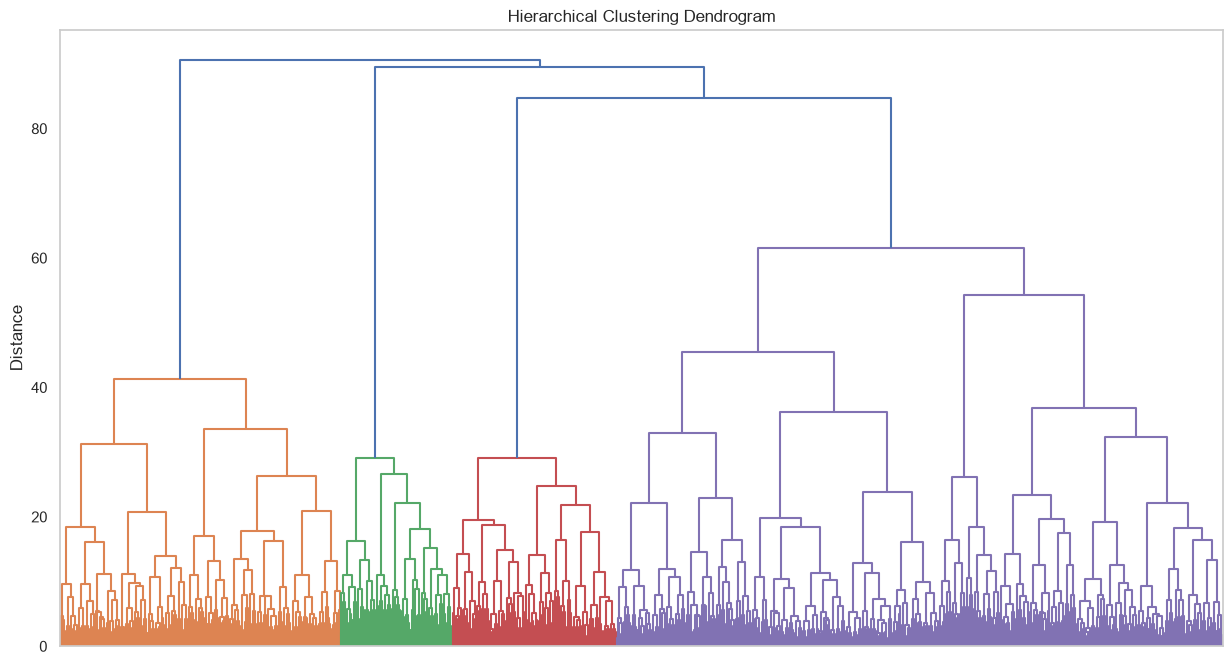

In [6]:
# Plot the dendrogram to estimate the number of clusters
plt.figure(figsize=(15, 8))
dendrogram(linked, orientation='top', no_labels=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.ylabel('Distance')
plt.grid(False)
plt.show()

### Observations
- The largest vertical gap without merges is between distances of about 62 and 85; cutting there gives 4 clusters, shown in different colors.
- A second, smaller gap between about 55 and 61 splits the largest (purple) group in two, giving 5 clusters.
- The dendrogram therefore suggests 4 or 5 clusters. Five clusters are used for K-means, as specified in the project, which is consistent with this analysis.

## 3. K-means Clustering

In [7]:
# Train K-means with 5 clusters and assign each customer to a cluster
km = KMeans(n_clusters=5, random_state=0)
clusters = km.fit_predict(X_scaled)

# Add the cluster labels to the full dataset, which still includes churn
gym_data['cluster'] = clusters

In [9]:
# Number and share of customers in each cluster
cluster_sizes = pd.DataFrame({
    'customers': gym_data['cluster'].value_counts().sort_index(),
    'share_%': (gym_data['cluster'].value_counts(normalize=True).sort_index() * 100).round(1)
})
cluster_sizes

,customers,share_%
cluster,,
0,1118,28.0
1,961,24.0
2,1035,25.9
3,600,15.0
4,286,7.2


### Observations
- K-means splits the customers into five clusters: three of similar size, clusters 0, 2 and 1 (1,118, 1,035 and 961 customers, or 28.0%, 25.9% and 24.0%), one medium-sized, cluster 3 (600 customers, 15.0%), and one small, cluster 4 (286 customers, 7.2%).
- Cluster numbers are only labels and have no meaning on their own; each cluster is described by its profile in the next section.